## 1. Load raw data and check PM2.5 coverage per station/year

In [2]:
# Install (Colab already has most of these)
!pip install lightgbm -q

import pandas as pd
import numpy as np

# 1. Load
df = pd.read_csv("dhaka_cams_hourly_2012_2026.csv")

# 2. Convert timestamp text to real datetime
df["timestamp"] = pd.to_datetime(df["timestamp"])

# 3. Basic look
print("Shape:", df.shape)
print("Stations:", df["station_id"].unique())

# 4. How much real PM2.5 data per station per year?
df["year"] = df["timestamp"].dt.year
coverage = (
    df.groupby(["year", "station_id"])["pm2_5_ug_m3"]
      .apply(lambda s: round(s.notna().mean() * 100, 1))
      .unstack()
)
print("\n% of hours with real PM2.5 data:")
print(coverage)

Shape: (389448, 19)
Stations: ['CAMS-1' 'CAMS-2' 'CAMS-3']

% of hours with real PM2.5 data:
station_id  CAMS-1  CAMS-2  CAMS-3
year                              
2012          13.6    11.0    15.4
2013          49.1    45.5    90.3
2014          82.5    29.0    89.0
2015          67.7    89.2    91.6
2016          39.7    40.0    67.2
2017          64.0    56.8    87.1
2018           2.6    81.1    77.7
2019          37.1    89.9    65.4
2020           0.0    84.5    86.1
2021           0.0    95.7    40.3
2022           0.0    92.6    90.2
2023          82.8    82.6    93.2
2024          86.6    91.2    82.7
2025           0.0     0.0     0.0
2026           0.0     0.0     0.0


## 2. Clean data: keep usable years, fix negatives, short-gap interpolation

In [3]:
# 1. Keep only usable years
df = df[(df["timestamp"] >= "2013-01-01") & (df["timestamp"] < "2025-01-01")].copy()

# 2. Drop the column that's ~88% empty
df = df.drop(columns=["vertical_wind_speed_ms", "year"])

# 3. Negative pollutant values are sensor errors -> make them NaN
pollutants = ["pm2_5_ug_m3","pm10_ug_m3","so2_ppb","no2_ppb","no_ppb","nox_ppb","co_ppm","o3_ppb"]
for c in pollutants:
    df.loc[df[c] < 0, c] = np.nan

# 4. Make every station have a complete hourly timeline (missing hours become NaN rows)
full_index = pd.date_range("2013-01-01 00:00", "2024-12-31 23:00", freq="h")
num_cols = [c for c in df.columns if c not in ["timestamp","station_id","station_name"]]

parts = []
for sid, g in df.groupby("station_id"):
    g = g.set_index("timestamp")[num_cols].reindex(full_index)
    # 5. Fill ONLY short gaps (max 3 hours in a row)
    g = g.interpolate(method="linear", limit=3, limit_area="inside")
    g["station_id"] = sid
    parts.append(g)

clean = pd.concat(parts)
clean.index.name = "timestamp"
clean = clean.reset_index()

# 6. Check result
print("Shape:", clean.shape)
print("\n% real PM2.5 per station after cleaning:")
print(clean.groupby("station_id")["pm2_5_ug_m3"].apply(lambda s: round(s.notna().mean()*100,1)))

Shape: (315576, 17)

% real PM2.5 per station after cleaning:
station_id
CAMS-1    44.6
CAMS-2    76.6
CAMS-3    84.8
Name: pm2_5_ug_m3, dtype: float64


## 3. Anomaly detection with Isolation Forest + save anomalies

Rows usable: 65777

Anomalies per station:
station_id
CAMS-1      2
CAMS-2    371
CAMS-3    285
Name: anomaly, dtype: int64


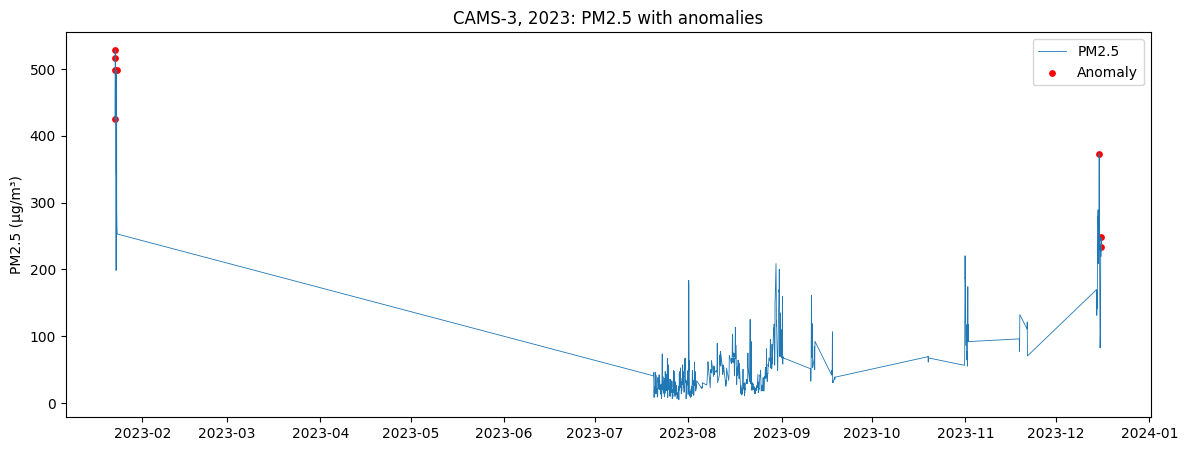

                 timestamp station_id  pm2_5_ug_m3  pm10_ug_m3  no2_ppb  \
211140 2013-02-01 12:00:00     CAMS-3       374.48     600.410    93.58   
218721 2013-12-14 09:00:00     CAMS-3       500.64     701.090    46.71   
130664 2015-11-28 08:00:00     CAMS-2       235.74     832.600    49.07   
219142 2013-12-31 22:00:00     CAMS-3       457.88     827.880    46.52   
130688 2015-11-29 08:00:00     CAMS-2       126.28     737.720    52.19   
218722 2013-12-14 10:00:00     CAMS-3       481.81     765.640    53.56   
210742 2013-01-15 22:00:00     CAMS-3       426.92     672.025    63.60   
130690 2015-11-29 10:00:00     CAMS-2       196.08     642.060    51.62   
130533 2015-11-22 21:00:00     CAMS-2        97.04     565.020    44.83   
130689 2015-11-29 09:00:00     CAMS-2       149.70     530.460    50.68   

        co_ppm  so2_ppb    o3_ppb  
211140    6.02   137.51  5.506667  
218721    5.81   130.26  2.410000  
130664   12.83   115.43  6.900000  
219142    6.64    71.96  1.920

In [4]:
from sklearn.ensemble import IsolationForest
import matplotlib.pyplot as plt

# Save cleaned data so you don't lose it if Colab resets
clean.to_csv("clean_hourly.csv", index=False)

# 1. Pick features for anomaly detection
feat = ["pm2_5_ug_m3", "pm10_ug_m3", "no2_ppb", "co_ppm", "so2_ppb", "o3_ppb"]

# 2. Keep only rows where ALL features are real (no filling)
data = clean.dropna(subset=feat).copy()
print("Rows usable:", len(data))

# 3. Train. contamination=0.01 means "flag the weirdest 1%"
iso = IsolationForest(n_estimators=200, contamination=0.01, random_state=42, n_jobs=-1)
iso.fit(data[feat])

# 4. Predict: -1 = anomaly, 1 = normal
data["anomaly"] = (iso.predict(data[feat]) == -1)
data["score"] = iso.decision_function(data[feat])   # lower = more weird

print("\nAnomalies per station:")
print(data.groupby("station_id")["anomaly"].sum())

# 5. Plot one station, one year
s = data[(data["station_id"] == "CAMS-3") & (data["timestamp"].dt.year == 2023)]
plt.figure(figsize=(14, 5))
plt.plot(s["timestamp"], s["pm2_5_ug_m3"], lw=0.6, label="PM2.5")
a = s[s["anomaly"]]
plt.scatter(a["timestamp"], a["pm2_5_ug_m3"], color="red", s=15, label="Anomaly")
plt.title("CAMS-3, 2023: PM2.5 with anomalies")
plt.ylabel("PM2.5 (µg/m³)")
plt.legend()
plt.show()

# 6. Top 10 weirdest hours
print(data.sort_values("score").head(10)[["timestamp", "station_id"] + feat])

## 4. Anomaly detection (simpler feature set) + scatter plot of anomalies

Rows usable: 110161
station_id
CAMS-1     29
CAMS-2    517
CAMS-3    556
Name: anomaly, dtype: int64


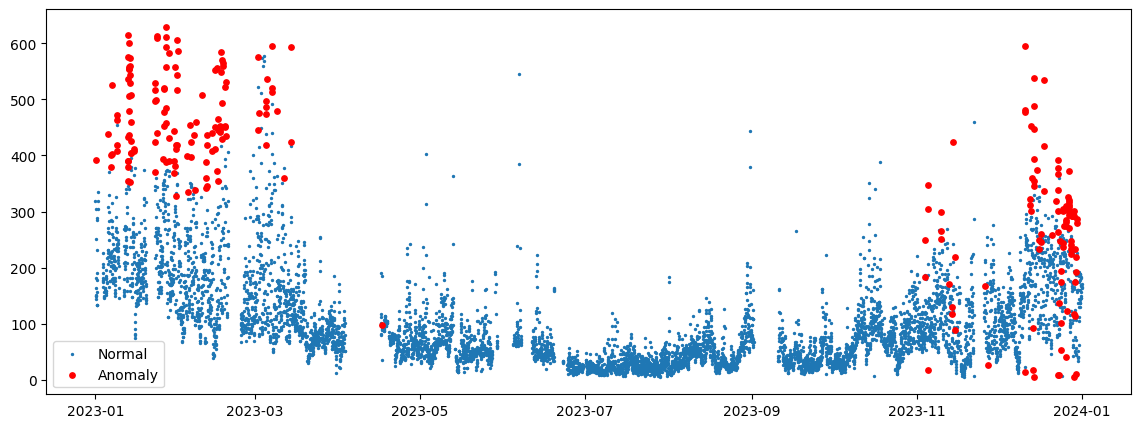

In [5]:
feat = ["pm2_5_ug_m3", "pm10_ug_m3", "no2_ppb", "co_ppm"]

data = clean.dropna(subset=feat).copy()
print("Rows usable:", len(data))

iso = IsolationForest(n_estimators=200, contamination=0.01, random_state=42, n_jobs=-1)
iso.fit(data[feat])
data["anomaly"] = (iso.predict(data[feat]) == -1)
data["score"] = iso.decision_function(data[feat])

print(data.groupby("station_id")["anomaly"].sum())

# Plot with dots only (no fake connecting lines)
s = data[(data["station_id"] == "CAMS-3") & (data["timestamp"].dt.year == 2023)]
plt.figure(figsize=(14, 5))
plt.scatter(s["timestamp"], s["pm2_5_ug_m3"], s=2, label="Normal")
a = s[s["anomaly"]]
plt.scatter(a["timestamp"], a["pm2_5_ug_m3"], color="red", s=15, label="Anomaly")
plt.legend(); plt.show()

data.to_csv("anomalies.csv", index=False)  # save for your report

## 5. Feature engineering: lags, rolling means, time features, 24h target + train/val/test split

In [6]:
clean = pd.read_csv("clean_hourly.csv", parse_dates=["timestamp"])
clean = clean.sort_values(["station_id", "timestamp"]).reset_index(drop=True)

HORIZON = 24
g = clean.groupby("station_id")["pm2_5_ug_m3"]

# Past PM2.5 values (lags)
for lag in [1, 2, 3, 6, 12, 24, 48, 168]:
    clean[f"pm25_lag{lag}"] = g.shift(lag)

# Rolling averages
clean["pm25_roll24"]  = g.transform(lambda s: s.rolling(24,  min_periods=12).mean())
clean["pm25_roll168"] = g.transform(lambda s: s.rolling(168, min_periods=72).mean())

# Time features
clean["hour"]  = clean["timestamp"].dt.hour
clean["month"] = clean["timestamp"].dt.month
clean["dow"]   = clean["timestamp"].dt.dayofweek
clean["station_code"] = clean["station_id"].astype("category").cat.codes

# Target = PM2.5 24 hours later
clean["target"] = g.shift(-HORIZON)

# Keep rows with a real target and a real last-hour value
model_df = clean.dropna(subset=["target", "pm25_lag1"]).copy()

# Time-based split
train = model_df[model_df["timestamp"] <  "2023-01-01"]
val   = model_df[(model_df["timestamp"] >= "2023-01-01") & (model_df["timestamp"] < "2024-01-01")]
test  = model_df[model_df["timestamp"] >= "2024-01-01"]
print("Train:", len(train), "| Val:", len(val), "| Test:", len(test))

drop_cols = ["timestamp", "station_id", "target"]
features = [c for c in model_df.columns if c not in drop_cols]
print("Number of features:", len(features))

Train: 161740 | Val: 22471 | Test: 22315
Number of features: 29


## 6. Train LightGBM v1 (24h-ahead) and evaluate on 2024 test set

[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.054474 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 6422
[LightGBM] [Info] Number of data points in the train set: 161740, number of used features: 29
[LightGBM] [Info] Start training from score 87.995969
Training until validation scores don't improve for 100 rounds
[200]	valid_0's l1: 33.3686	valid_0's l2: 3106
Early stopping, best iteration is:
[125]	valid_0's l1: 32.7744	valid_0's l2: 3069.3

--- TEST RESULTS (2024) ---
LightGBM                     MAE= 29.35  RMSE= 47.85  R2=0.554
Baseline (same as now)       MAE= 33.52  RMSE= 57.93  R2=0.342


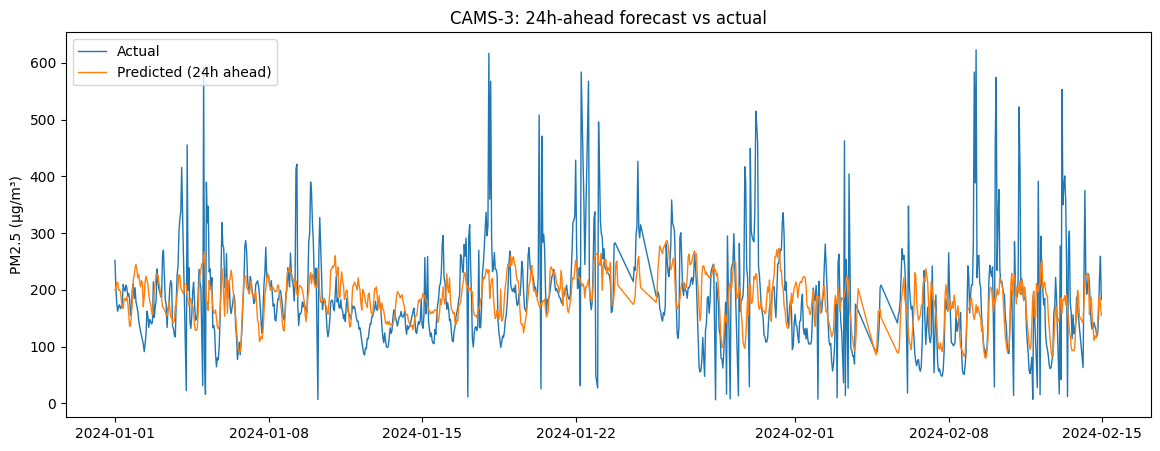


Top 10 features:
pm25_roll168               666
temp_c                     566
month                      535
pm25_roll24                485
barometric_pressure_hpa    437
pm2_5_ug_m3                405
pm25_lag24                 387
pm25_lag168                384
pm25_lag48                 316
hour                       310
dtype: int32


In [7]:
import lightgbm as lgb
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

X_train, y_train = train[features], train["target"]
X_val,   y_val   = val[features],   val["target"]
X_test,  y_test  = test[features],  test["target"]

# 1. Train (stops automatically when validation stops improving)
model = lgb.LGBMRegressor(
    n_estimators=2000,
    learning_rate=0.03,
    num_leaves=63,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1,
)
model.fit(
    X_train, y_train,
    eval_set=[(X_val, y_val)],
    eval_metric="mae",
    callbacks=[lgb.early_stopping(100), lgb.log_evaluation(200)],
)

# 2. Predict on the test set (2024, never seen during training)
pred = model.predict(X_test)

# 3. Scores
def report(name, y, p):
    mae = mean_absolute_error(y, p)
    rmse = np.sqrt(mean_squared_error(y, p))
    r2 = r2_score(y, p)
    print(f"{name:28s} MAE={mae:6.2f}  RMSE={rmse:6.2f}  R2={r2:5.3f}")

print("\n--- TEST RESULTS (2024) ---")
report("LightGBM", y_test, pred)

# 4. Baseline: "tomorrow = same hour as today" (to prove the model is actually useful)
m = X_test["pm25_lag24"].notna()
# lag24 is 24h before the current hour, so use pm2_5 now as the naive guess
naive = X_test.loc[m, "pm2_5_ug_m3"]
mm = naive.notna()
report("Baseline (same as now)", y_test[m][mm], naive[mm])

# 5. Plot: actual vs predicted for CAMS-3, 2024
t = test.copy()
t["pred"] = pred
s = t[(t["station_id"] == "CAMS-3") & (t["timestamp"] >= "2024-01-01") & (t["timestamp"] < "2024-02-15")]
plt.figure(figsize=(14, 5))
plt.plot(s["timestamp"], s["target"], label="Actual", lw=1)
plt.plot(s["timestamp"], s["pred"], label="Predicted (24h ahead)", lw=1)
plt.ylabel("PM2.5 (µg/m³)"); plt.legend(); plt.title("CAMS-3: 24h-ahead forecast vs actual")
plt.show()

# 6. Which features mattered most
imp = pd.Series(model.feature_importances_, index=features).sort_values(ascending=False)
print("\nTop 10 features:")
print(imp.head(10))

# Save model
model.booster_.save_model("pm25_lgbm.txt")

## 7. LightGBM v2: cross-station features + log-target

In [8]:
# 1. Add all 3 stations' PM2.5 (same hour) as features
piv = clean.pivot(index="timestamp", columns="station_id", values="pm2_5_ug_m3")
piv.columns = [f"pm25_{c}" for c in piv.columns]
clean2 = clean.merge(piv.reset_index(), on="timestamp", how="left")

model_df2 = clean2.dropna(subset=["target", "pm25_lag1"]).copy()
train2 = model_df2[model_df2["timestamp"] <  "2023-01-01"]
val2   = model_df2[(model_df2["timestamp"] >= "2023-01-01") & (model_df2["timestamp"] < "2024-01-01")]
test2  = model_df2[model_df2["timestamp"] >= "2024-01-01"]

features2 = [c for c in model_df2.columns if c not in ["timestamp", "station_id", "target"]]

# 2. Train on log(target) so huge spikes don't dominate
model2 = lgb.LGBMRegressor(
    n_estimators=2000, learning_rate=0.03, num_leaves=63,
    subsample=0.8, colsample_bytree=0.8, random_state=42, n_jobs=-1, verbose=-1,
)
model2.fit(
    train2[features2], np.log1p(train2["target"]),
    eval_set=[(val2[features2], np.log1p(val2["target"]))],
    eval_metric="mae",
    callbacks=[lgb.early_stopping(100), lgb.log_evaluation(0)],
)

# 3. Predict and convert back from log
pred2 = np.expm1(model2.predict(test2[features2]))

print("--- TEST RESULTS (2024) ---")
report("LightGBM v1", y_test, pred)
report("LightGBM v2 (cross-station+log)", test2["target"], pred2)

Training until validation scores don't improve for 100 rounds
Early stopping, best iteration is:
[120]	valid_0's l1: 0.380349	valid_0's l2: 0.273191
--- TEST RESULTS (2024) ---
LightGBM v1                  MAE= 29.35  RMSE= 47.85  R2=0.554
LightGBM v2 (cross-station+log) MAE= 28.42  RMSE= 49.43  R2=0.524


## 8. Per-station accuracy, high-pollution detection, scatter + feature importance plots

--- Per station (v1) ---
CAMS-1                       MAE= 29.59  RMSE= 46.49  R2=0.561
CAMS-2                       MAE= 23.94  RMSE= 37.56  R2=0.569
CAMS-3                       MAE= 35.32  RMSE= 58.70  R2=0.519

--- High pollution (>150) detection ---
Real high hours      : 3497
Caught by model      : 2117 (60.5%)
False alarms         : 1307


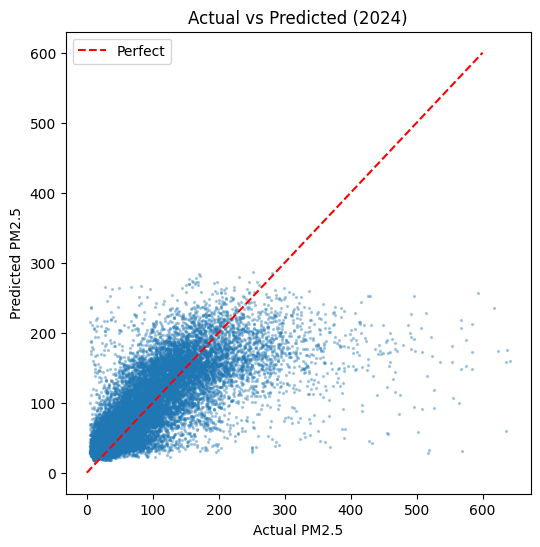

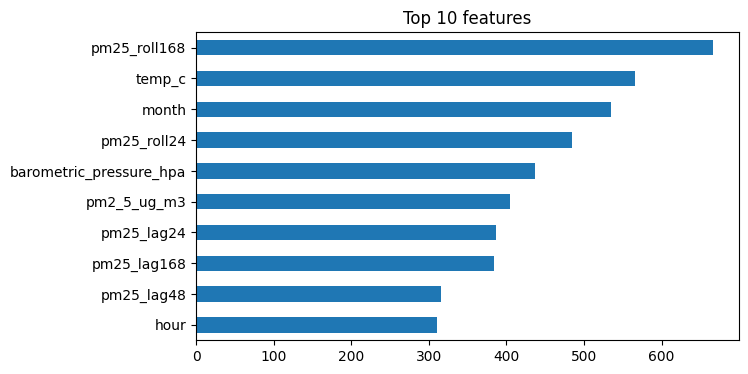

In [9]:
t = test.copy()
t["pred"] = pred

# 1. Accuracy per station
print("--- Per station (v1) ---")
for sid, g in t.groupby("station_id"):
    report(sid, g["target"], g["pred"])

# 2. Can it catch high-pollution hours? (PM2.5 > 150 = very unhealthy)
THR = 150
actual_high = t["target"] > THR
pred_high   = t["pred"]   > THR
tp = (actual_high & pred_high).sum()
print("\n--- High pollution (>150) detection ---")
print("Real high hours      :", actual_high.sum())
print("Caught by model      :", tp, f"({tp / actual_high.sum() * 100:.1f}%)")
print("False alarms         :", (~actual_high & pred_high).sum())

# 3. Actual vs predicted scatter (nice figure for report)
plt.figure(figsize=(6, 6))
plt.scatter(t["target"], t["pred"], s=2, alpha=0.3)
plt.plot([0, 600], [0, 600], "r--", label="Perfect")
plt.xlabel("Actual PM2.5"); plt.ylabel("Predicted PM2.5")
plt.title("Actual vs Predicted (2024)"); plt.legend()
plt.savefig("fig_scatter.png", dpi=200, bbox_inches="tight")
plt.show()

# 4. Feature importance figure
imp.head(10).sort_values().plot.barh(figsize=(7, 4), title="Top 10 features")
plt.savefig("fig_importance.png", dpi=200, bbox_inches="tight")
plt.show()

# 5. Save the forecast table
t[["timestamp", "station_id", "target", "pred"]].to_csv("forecast_results_2024.csv", index=False)

## 9. Single-timestamp forecast helper (any station + time → 24h PM2.5 + AQI risk)

In [10]:
def risk_level(x):
    if x <= 12:    return "Good"
    if x <= 35.4:  return "Moderate"
    if x <= 55.4:  return "Unhealthy for sensitive groups"
    if x <= 150.4: return "Unhealthy"
    if x <= 250.4: return "Very unhealthy"
    return "Hazardous"

def forecast(station, when):
    """Give a time + station, get PM2.5 prediction for 24 hours later."""
    when = pd.Timestamp(when)
    row = clean[(clean["station_id"] == station) & (clean["timestamp"] == when)]
    if row.empty or pd.isna(row["pm25_lag1"].iloc[0]):
        print("Not enough real data at that time, try another timestamp.")
        return
    p = model.predict(row[features])[0]
    print(f"Station         : {station}")
    print(f"Now             : {when}")
    print(f"Forecast for    : {when + pd.Timedelta(hours=24)}")
    print(f"Predicted PM2.5 : {p:.1f} µg/m³  ->  {risk_level(p)}")
    actual = row["target"].iloc[0]
    if not pd.isna(actual):
        print(f"Actual PM2.5    : {actual:.1f} µg/m³  ->  {risk_level(actual)}")

forecast("CAMS-2", "2024-01-20 12:00")
forecast("CAMS-3", "2024-07-15 09:00")
forecast("CAMS-1", "2024-12-10 18:00")

Station         : CAMS-2
Now             : 2024-01-20 12:00:00
Forecast for    : 2024-01-21 12:00:00
Predicted PM2.5 : 136.2 µg/m³  ->  Unhealthy
Actual PM2.5    : 199.4 µg/m³  ->  Very unhealthy
Station         : CAMS-3
Now             : 2024-07-15 09:00:00
Forecast for    : 2024-07-16 09:00:00
Predicted PM2.5 : 42.1 µg/m³  ->  Unhealthy for sensitive groups
Actual PM2.5    : 42.3 µg/m³  ->  Unhealthy for sensitive groups
Station         : CAMS-1
Now             : 2024-12-10 18:00:00
Forecast for    : 2024-12-11 18:00:00
Predicted PM2.5 : 130.2 µg/m³  ->  Unhealthy
Actual PM2.5    : 108.6 µg/m³  ->  Unhealthy


## 10. Quick alert-threshold check (catch rate vs false alarms)

In [11]:
for thr in [100, 120, 150]:
    alert = t["pred"] > thr
    real  = t["target"] > 150
    caught = (alert & real).sum() / real.sum() * 100
    false  = (alert & ~real).sum()
    print(f"Alert if predicted > {thr}: catches {caught:.1f}% of real high hours, false alarms = {false}")

Alert if predicted > 100: catches 90.4% of real high hours, false alarms = 4131
Alert if predicted > 120: catches 83.0% of real high hours, false alarms = 2848
Alert if predicted > 150: catches 60.5% of real high hours, false alarms = 1307


## 11. Sanity checks: model reload, leakage, baseline comparison

In [12]:
import time

results = []
def check(name, ok, detail=""):
    results.append(ok)
    print(f"[{'PASS' if ok else 'FAIL'}] {name} {detail}")

# ---------- 1. Model saves/loads correctly ----------
loaded = lgb.Booster(model_file="pm25_lgbm.txt")
check("Saved model reloads & gives same predictions",
      np.allclose(loaded.predict(X_test), pred))

# ---------- 2. Output sanity ----------
check("No NaN in predictions", not np.isnan(pred).any())
check("No negative predictions", (pred >= 0).all(), f"(min={pred.min():.1f})")
check("Predictions in realistic range (0-1000)", pred.max() < 1000, f"(max={pred.max():.1f})")

# ---------- 3. Robustness: weird inputs shouldn't crash ----------
try:
    row = X_test.iloc[[0]].copy()
    row[:] = np.nan                       # all values missing
    model.predict(row)
    check("Handles all-missing input without crashing", True)
except Exception as e:
    check("Handles all-missing input without crashing", False, str(e))

try:
    row = X_test.iloc[[0]].copy()
    row["pm2_5_ug_m3"] = 5000             # absurd value
    p = model.predict(row)[0]
    check("Handles absurd input (PM2.5=5000)", np.isfinite(p), f"(pred={p:.1f})")
except Exception as e:
    check("Handles absurd input (PM2.5=5000)", False, str(e))

# ---------- 4. Logic test: dirtier air now -> higher forecast ----------
lo = X_test.iloc[[0]].copy()
hi = lo.copy()
for c in ["pm2_5_ug_m3", "pm25_lag1", "pm25_lag24", "pm25_roll24", "pm25_roll168"]:
    lo[c], hi[c] = 20, 250
p_lo, p_hi = model.predict(lo)[0], model.predict(hi)[0]
check("Higher recent PM2.5 -> higher forecast", p_hi > p_lo, f"(low={p_lo:.1f}, high={p_hi:.1f})")

# ---------- 5. Every station runs ----------
for sid in clean["station_id"].unique():
    sub = X_test[test["station_id"] == sid]
    ok = len(sub) > 0 and np.isfinite(model.predict(sub)).all()
    check(f"Station {sid} predicts fine", ok, f"({len(sub)} rows)")

# ---------- 6. Speed ----------
t0 = time.time(); model.predict(X_test.iloc[[0]]); one = time.time() - t0
t0 = time.time(); model.predict(X_test);            allp = time.time() - t0
check("Single prediction < 1 sec", one < 1, f"({one*1000:.1f} ms)")
check(f"{len(X_test)} predictions < 10 sec", allp < 10, f"({allp:.2f} s)")

# ---------- 7. Anomaly detector ----------
normal = pd.DataFrame([data[feat].median()])
spike  = pd.DataFrame([{"pm2_5_ug_m3": 700, "pm10_ug_m3": 900, "no2_ppb": 150, "co_ppm": 20}])
check("Normal reading NOT flagged", iso.predict(normal)[0] == 1)
check("Obvious extreme spike IS flagged", iso.predict(spike)[0] == -1)
check("Flag rate near 1% setting", 0.005 < data["anomaly"].mean() < 0.02,
      f"({data['anomaly'].mean()*100:.2f}%)")

# ---------- Summary ----------
print(f"\n=== {sum(results)}/{len(results)} checks passed ===")

[PASS] Saved model reloads & gives same predictions 
[PASS] No NaN in predictions 
[PASS] No negative predictions (min=18.7)
[PASS] Predictions in realistic range (0-1000) (max=286.9)
[PASS] Handles all-missing input without crashing 
[PASS] Handles absurd input (PM2.5=5000) (pred=170.8)
[PASS] Higher recent PM2.5 -> higher forecast (low=58.5, high=218.0)
[PASS] Station CAMS-1 predicts fine (7584 rows)
[PASS] Station CAMS-2 predicts fine (7893 rows)
[PASS] Station CAMS-3 predicts fine (6838 rows)


/tmp/ipykernel_1630/1661760602.py:21: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value 'nan' has dtype incompatible with int32, please explicitly cast to a compatible dtype first.
  row[:] = np.nan                       # all values missing
/tmp/ipykernel_1630/1661760602.py:21: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value 'nan' has dtype incompatible with int32, please explicitly cast to a compatible dtype first.
  row[:] = np.nan                       # all values missing
/tmp/ipykernel_1630/1661760602.py:21: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value 'nan' has dtype incompatible with int32, please explicitly cast to a compatible dtype first.
  row[:] = np.nan                       # all values missing
/tmp/ipykernel_1630/1661760602.py:21: FutureWarning: Setting an item of i

[PASS] Single prediction < 1 sec (2.3 ms)
[PASS] 22315 predictions < 10 sec (0.13 s)
[PASS] Normal reading NOT flagged 
[PASS] Obvious extreme spike IS flagged 
[PASS] Flag rate near 1% setting (1.00%)

=== 15/15 checks passed ===


## 12. Recursive 72h rollout forecast (station by station)

Training until validation scores don't improve for 50 rounds
Early stopping, best iteration is:
[223]	valid_0's l2: 959.341
Backtest on 150 random start points in 2024

Horizon   Model MAE   Baseline MAE
   1 h       13.52       15.07
   6 h       26.68       33.56
  12 h       27.65       39.55
  24 h       29.69       32.22
  48 h       28.83       29.30
  72 h       37.90       38.67


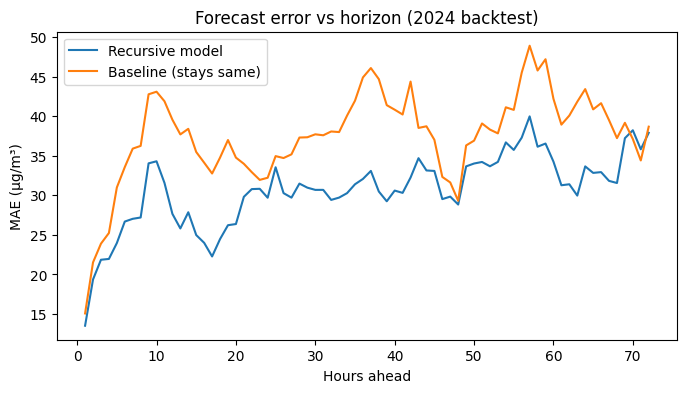


CAMS-1: last real data = 2024-12-31 23:00:00
  Day +1:  164.4 µg/m³ -> Very unhealthy
  Day +2:  166.8 µg/m³ -> Very unhealthy
  Day +3:  164.8 µg/m³ -> Very unhealthy

CAMS-2: last real data = 2024-12-31 23:00:00
  Day +1:  143.6 µg/m³ -> Unhealthy
  Day +2:  157.1 µg/m³ -> Very unhealthy
  Day +3:  163.0 µg/m³ -> Very unhealthy

CAMS-3: last real data = 2024-12-16 10:00:00
  Day +1:  226.7 µg/m³ -> Very unhealthy
  Day +2:  242.6 µg/m³ -> Very unhealthy
  Day +3:  259.6 µg/m³ -> Hazardous


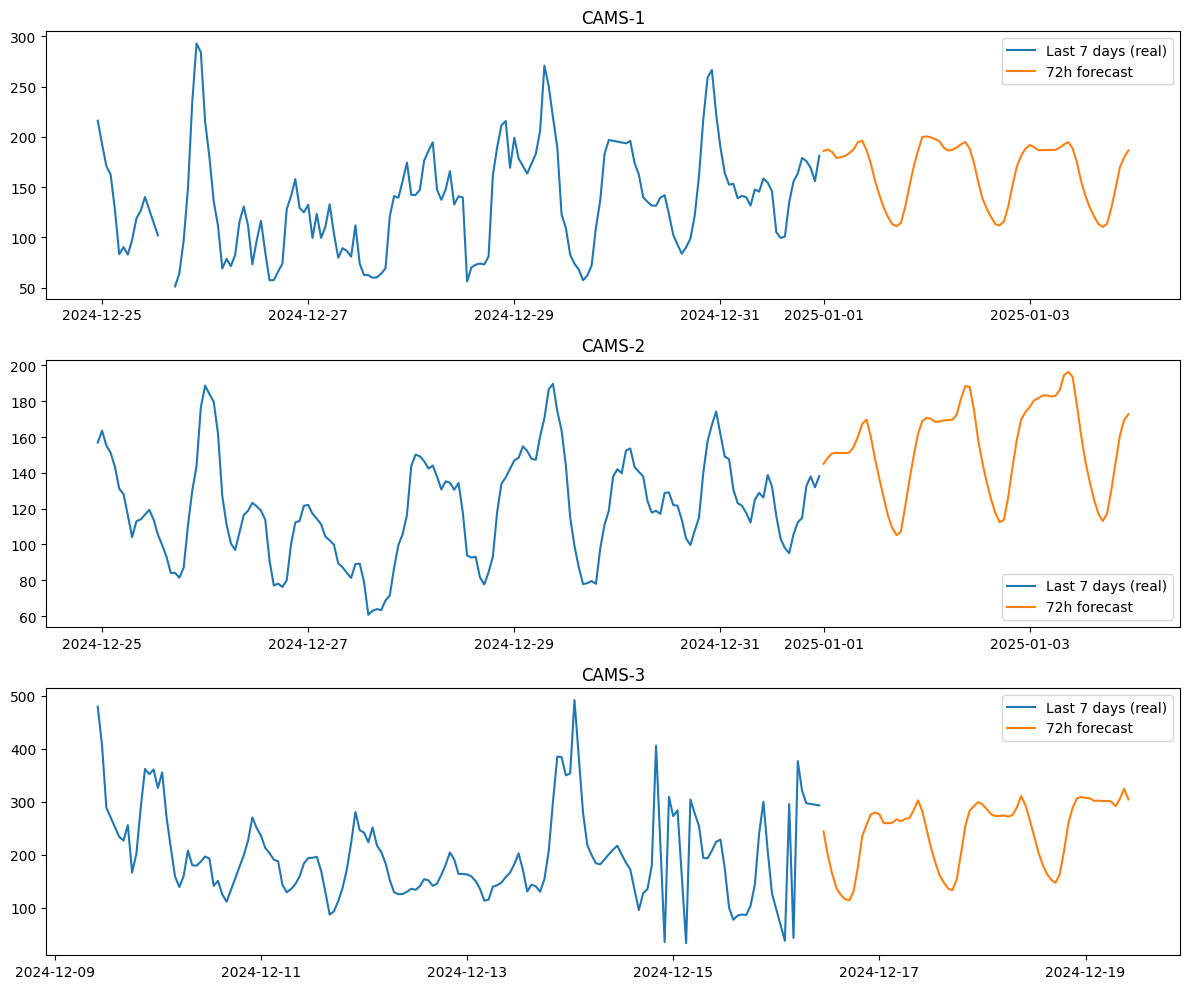

In [13]:
H = 72
lags = [1, 2, 3, 6, 12, 24, 48, 168]
code_map = {"CAMS-1": 0, "CAMS-2": 1, "CAMS-3": 2}

# ---------- 1. Build features (PM2.5 history + time only) ----------
d = clean[["timestamp", "station_id", "pm2_5_ug_m3"]].sort_values(["station_id", "timestamp"]).reset_index(drop=True)
g = d.groupby("station_id")["pm2_5_ug_m3"]
d["lag0"] = d["pm2_5_ug_m3"]
for k in lags:
    d[f"lag{k}"] = g.shift(k)
d["roll24"]  = g.transform(lambda s: s.rolling(24,  min_periods=12).mean())
d["roll168"] = g.transform(lambda s: s.rolling(168, min_periods=72).mean())
d["hour"], d["month"], d["dow"] = d.timestamp.dt.hour, d.timestamp.dt.month, d.timestamp.dt.dayofweek
d["station_code"] = d["station_id"].map(code_map)
d["target"] = g.shift(-1)          # PM2.5 one hour later

cols = ["lag0"] + [f"lag{k}" for k in lags] + ["roll24", "roll168", "hour", "month", "dow", "station_code"]
m1 = d.dropna(subset=["target", "lag0"])
tr = m1[m1.timestamp < "2023-01-01"]
va = m1[(m1.timestamp >= "2023-01-01") & (m1.timestamp < "2024-01-01")]

# ---------- 2. Train the 1-hour-ahead model ----------
model_h = lgb.LGBMRegressor(n_estimators=1000, learning_rate=0.05, num_leaves=31,
                            random_state=42, n_jobs=-1, verbose=-1)
model_h.fit(tr[cols], tr["target"], eval_set=[(va[cols], va["target"])],
            callbacks=[lgb.early_stopping(50), lgb.log_evaluation(0)])

# ---------- 3. Rollout machinery ----------
def make_x(arr, t, code):
    f = {"lag0": arr[-1]}
    for k in lags:
        f[f"lag{k}"] = arr[-1 - k]
    a24, a168 = arr[-24:], arr[-168:]
    f["roll24"]  = np.nanmean(a24)  if np.isfinite(a24).sum()  >= 12 else np.nan
    f["roll168"] = np.nanmean(a168) if np.isfinite(a168).sum() >= 72 else np.nan
    f["hour"], f["month"], f["dow"], f["station_code"] = t.hour, t.month, t.dayofweek, code
    return pd.DataFrame([f])[cols]

def rollout(hist169, t_last, code, H=H):
    """hist169 = last 169 hourly values ending at t_last. Returns next H hourly predictions."""
    hist, preds = list(hist169), []
    for h in range(H):
        t = t_last + pd.Timedelta(hours=h)
        p = float(model_h.predict(make_x(np.array(hist[-169:], float), t, code))[0])
        preds.append(p)
        hist.append(p)               # feed prediction back in
    return np.array(preds)

# ---------- 4. BACKTEST: 150 random starts in 2024 ----------
rng = np.random.default_rng(42)
err_m, err_p = [], []
for sid, grp in d.groupby("station_id"):
    s = grp.set_index("timestamp")["pm2_5_ug_m3"]
    v, ts = s.values, s.index
    ok = [i for i in np.where((ts >= "2024-01-01") & (ts < "2024-12-25"))[0]
          if i >= 168 and np.isfinite(v[i])
          and np.isfinite(v[i-168:i+1]).sum() >= 120
          and np.isfinite(v[i+1:i+1+H]).sum() >= 0.8 * H]
    for i in rng.choice(ok, size=min(50, len(ok)), replace=False):
        truth = v[i+1:i+1+H]
        pr = rollout(v[i-168:i+1], ts[i], code_map[sid])
        err_m.append(np.abs(pr - truth))          # NaN where truth missing
        err_p.append(np.abs(v[i] - truth))        # baseline: "stays same as now"

mae_m, mae_p = np.nanmean(err_m, axis=0), np.nanmean(err_p, axis=0)
print(f"Backtest on {len(err_m)} random start points in 2024\n")
print("Horizon   Model MAE   Baseline MAE")
for h in [1, 6, 12, 24, 48, 72]:
    print(f"{h:>4} h    {mae_m[h-1]:8.2f}    {mae_p[h-1]:8.2f}")

plt.figure(figsize=(8, 4))
plt.plot(range(1, H+1), mae_m, label="Recursive model")
plt.plot(range(1, H+1), mae_p, label="Baseline (stays same)")
plt.xlabel("Hours ahead"); plt.ylabel("MAE (µg/m³)"); plt.legend()
plt.title("Forecast error vs horizon (2024 backtest)")
plt.savefig("fig_error_vs_horizon.png", dpi=200, bbox_inches="tight"); plt.show()

# ---------- 5. FUTURE FORECAST from the last good data point ----------
fig, axes = plt.subplots(3, 1, figsize=(12, 10))
for ax, (sid, grp) in zip(axes, d.groupby("station_id")):
    s = grp.set_index("timestamp")["pm2_5_ug_m3"]
    v = s.values
    i = next(j for j in range(len(v) - 1, 168, -1)
             if np.isfinite(v[j]) and np.isfinite(v[j-168:j+1]).sum() >= 120)
    fc = rollout(v[i-168:i+1], s.index[i], code_map[sid])
    daily = fc.reshape(3, 24).mean(axis=1)
    print(f"\n{sid}: last real data = {s.index[i]}")
    for n, x in enumerate(daily, 1):
        print(f"  Day +{n}: {x:6.1f} µg/m³ -> {risk_level(x)}")
    ax.plot(s.index[i-168:i+1], v[i-168:i+1], label="Last 7 days (real)")
    ax.plot(pd.date_range(s.index[i], periods=H+1, freq="h")[1:], fc, label="72h forecast")
    ax.set_title(sid); ax.legend()
plt.tight_layout(); plt.savefig("fig_forecast.png", dpi=200, bbox_inches="tight"); plt.show()

## 13. Monthly series + SARIMA long-term validation (2023–2024)

Months total: 144 | months with no data: 0

--- Validation on 2023-2024 (monthly) ---
SARIMA          MAE = 27.70
Seasonal average MAE = 12.69


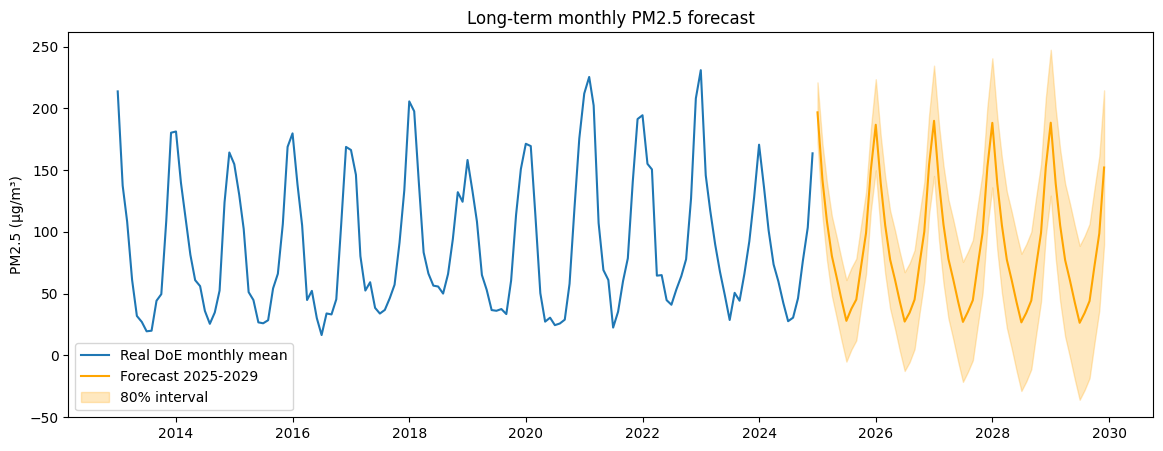


Yearly average forecast (µg/m³):
      forecast   low   high
2025      88.9  57.1  120.7
2026      87.3  47.8  126.9
2027      87.4  39.4  135.4
2028      86.9  31.9  141.9
2029      86.6  24.8  148.4


In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.statespace.sarimax import SARIMAX
import warnings; warnings.filterwarnings("ignore")

# 1. Monthly average PM2.5 from REAL data only (a station-month needs >=200 real hours)
c = pd.read_csv("clean_hourly.csv", parse_dates=["timestamp"])
c["month"] = c["timestamp"].dt.to_period("M").dt.to_timestamp()
st = c.groupby(["month", "station_id"])["pm2_5_ug_m3"].agg(["mean", "count"]).reset_index()
st.loc[st["count"] < 200, "mean"] = np.nan
monthly = st.groupby("month")["mean"].mean().asfreq("MS")
print("Months total:", len(monthly), "| months with no data:", monthly.isna().sum())

# 2. VALIDATE: train to 2022, forecast 2023-2024, compare with a simple baseline
train_m, test_m = monthly[:"2022-12"], monthly["2023-01":]
mod = SARIMAX(train_m, order=(1, 1, 1), seasonal_order=(1, 1, 0, 12),
              enforce_stationarity=False, enforce_invertibility=False).fit(disp=False)
fc = mod.get_forecast(len(test_m)).predicted_mean
fc.index = test_m.index

# Baseline: average of each calendar month in the training years
clim = train_m.groupby(train_m.index.month).mean()
base = pd.Series([clim[m] for m in test_m.index.month], index=test_m.index)

ok = test_m.notna()
print("\n--- Validation on 2023-2024 (monthly) ---")
print(f"SARIMA          MAE = {np.mean(np.abs(fc[ok] - test_m[ok])):.2f}")
print(f"Seasonal average MAE = {np.mean(np.abs(base[ok] - test_m[ok])):.2f}")

# 3. FINAL: refit on everything through 2024, forecast 60 months (2025-2029)
final = SARIMAX(monthly, order=(1, 1, 1), seasonal_order=(1, 1, 0, 12),
                enforce_stationarity=False, enforce_invertibility=False).fit(disp=False)
f = final.get_forecast(60)
mean = f.predicted_mean
ci = f.conf_int(alpha=0.2)          # 80% band
mean.index = ci.index = pd.date_range("2025-01-01", periods=60, freq="MS")

# 4. Plot
plt.figure(figsize=(14, 5))
plt.plot(monthly.index, monthly.values, label="Real DoE monthly mean")
plt.plot(mean.index, mean.values, color="orange", label="Forecast 2025-2029")
plt.fill_between(ci.index, ci.iloc[:, 0], ci.iloc[:, 1], color="orange", alpha=0.25, label="80% interval")
plt.ylabel("PM2.5 (µg/m³)"); plt.title("Long-term monthly PM2.5 forecast")
plt.legend(); plt.savefig("fig_longterm_forecast.png", dpi=200, bbox_inches="tight"); plt.show()

# 5. Yearly summary table
yr = pd.DataFrame({"forecast": mean, "low": ci.iloc[:, 0], "high": ci.iloc[:, 1]}).groupby(mean.index.year).mean().round(1)
print("\nYearly average forecast (µg/m³):"); print(yr)
mean.to_csv("longterm_forecast_2025_2029.csv")

## 14. Rebuild cleaned hourly data from raw CSV (session-reset safety)

In [15]:
import pandas as pd
import numpy as np

# 1. Load (make sure dhaka_cams_hourly_2012_2026.csv is re-uploaded first)
df = pd.read_csv("dhaka_cams_hourly_2012_2026.csv")
df["timestamp"] = pd.to_datetime(df["timestamp"])

# 2. Same cleaning as before
df = df[(df["timestamp"] >= "2013-01-01") & (df["timestamp"] < "2025-01-01")].copy()
df = df.drop(columns=["vertical_wind_speed_ms"])

pollutants = ["pm2_5_ug_m3","pm10_ug_m3","so2_ppb","no2_ppb","no_ppb","nox_ppb","co_ppm","o3_ppb"]
for col in pollutants:
    df.loc[df[col] < 0, col] = np.nan

full_index = pd.date_range("2013-01-01 00:00", "2024-12-31 23:00", freq="h")
num_cols = [c for c in df.columns if c not in ["timestamp", "station_id", "station_name"]]

parts = []
for sid, g in df.groupby("station_id"):
    g = g.set_index("timestamp")[num_cols].reindex(full_index)
    g = g.interpolate(method="linear", limit=3, limit_area="inside")
    g["station_id"] = sid
    parts.append(g)

clean = pd.concat(parts)
clean.index.name = "timestamp"
clean = clean.reset_index()

clean.to_csv("clean_hourly.csv", index=False)
print("Saved:", clean.shape)

Saved: (315576, 17)


## 15. SARIMA on log scale: try several orders, pick best, produce 2025–2029 outlook

    order      seasonal       MAE
(2, 0, 0) (0, 1, 1, 12) 12.636185
(1, 0, 0) (0, 1, 1, 12) 12.722201
(1, 0, 1) (0, 1, 1, 12) 12.813207
(1, 0, 1) (1, 0, 0, 12) 18.719175
(2, 0, 0) (1, 0, 0, 12) 18.952344

Seasonal-average baseline MAE: 12.69

Using SARIMA (log scale): (2, 0, 0) (0, 1, 1, 12)


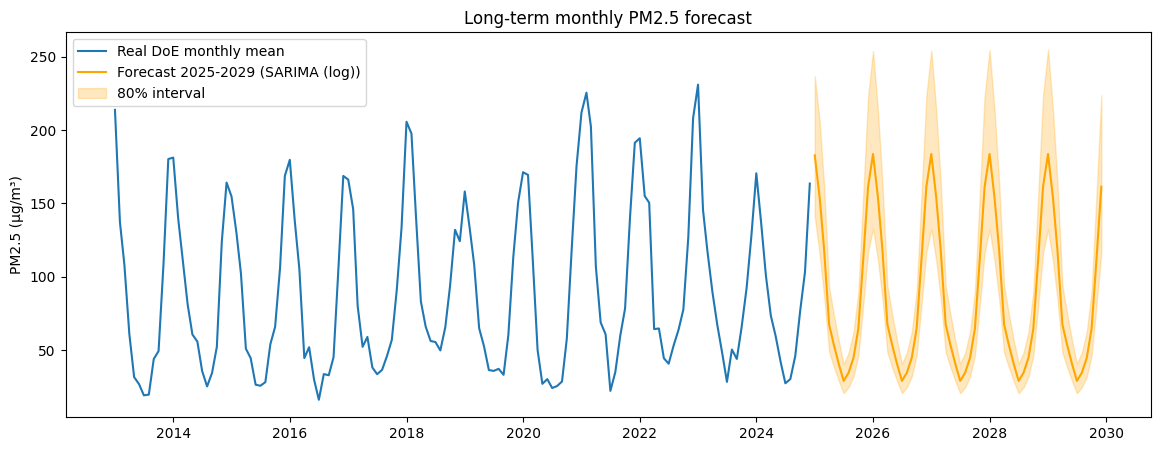

      forecast   low   high
2025      88.7  65.3  120.4
2026      88.8  64.1  122.9
2027      88.8  64.0  123.0
2028      88.8  64.0  123.2
2029      88.8  63.9  123.3


In [16]:
# Uses `monthly`, `train_m`, `test_m`, `ok`, `base` from Step 11 (rerun Step 11 first if the session reset)
logm = np.log1p(monthly)
train_l = logm[:"2022-12"]
base_mae = np.mean(np.abs(base[ok] - test_m[ok]))

# 1. Try several settings on log scale, score on 2023-2024 in the original units
cands = [((p, 0, q), s) for p, q in [(1, 0), (1, 1), (2, 0)]
         for s in [(1, 0, 0, 12), (1, 1, 0, 12), (0, 1, 1, 12)]]
rows = []
for o, s in cands:
    try:
        m = SARIMAX(train_l, order=o, seasonal_order=s,
                    enforce_stationarity=False, enforce_invertibility=False).fit(disp=False)
        p = np.expm1(m.get_forecast(len(test_m)).predicted_mean.values)
        rows.append((o, s, np.mean(np.abs(p[ok.values] - test_m.values[ok.values]))))
    except Exception:
        pass
res = pd.DataFrame(rows, columns=["order", "seasonal", "MAE"]).sort_values("MAE")
print(res.head(5).to_string(index=False))
print("\nSeasonal-average baseline MAE:", round(base_mae, 2))

# 2. Final forecast 2025-2029 with the winner (model if it beats baseline, else seasonal average)
idx = pd.date_range("2025-01-01", periods=60, freq="MS")
best = res.iloc[0]
if best["MAE"] < base_mae:
    print("\nUsing SARIMA (log scale):", best["order"], best["seasonal"])
    fin = SARIMAX(logm, order=best["order"], seasonal_order=best["seasonal"],
                  enforce_stationarity=False, enforce_invertibility=False).fit(disp=False)
    f = fin.get_forecast(60)
    mean = pd.Series(np.expm1(f.predicted_mean.values), index=idx)
    ci = np.expm1(f.conf_int(alpha=0.2)).clip(lower=0)
    lo, hi = pd.Series(ci.iloc[:, 0].values, index=idx), pd.Series(ci.iloc[:, 1].values, index=idx)
    label = "SARIMA (log)"
else:
    print("\nBaseline wins -> using seasonal average with an empirical band")
    clim_all = monthly.groupby(monthly.index.month).mean()
    spread = (monthly - monthly.index.month.map(clim_all).values).groupby(monthly.index.month).std()
    mean = pd.Series([clim_all[m] for m in idx.month], index=idx)
    lo = (mean - 1.28 * pd.Series([spread[m] for m in idx.month], index=idx)).clip(lower=0)
    hi = mean + 1.28 * pd.Series([spread[m] for m in idx.month], index=idx)
    label = "Seasonal average"

# 3. Plot + table
plt.figure(figsize=(14, 5))
plt.plot(monthly.index, monthly.values, label="Real DoE monthly mean")
plt.plot(mean.index, mean.values, color="orange", label=f"Forecast 2025-2029 ({label})")
plt.fill_between(idx, lo, hi, color="orange", alpha=0.25, label="80% interval")
plt.ylabel("PM2.5 (µg/m³)"); plt.title("Long-term monthly PM2.5 forecast"); plt.legend()
plt.savefig("fig_longterm_forecast.png", dpi=200, bbox_inches="tight"); plt.show()

yr = pd.DataFrame({"forecast": mean, "low": lo, "high": hi}).groupby(idx.year).mean().round(1)
print(yr)
mean.to_csv("longterm_forecast_2025_2029.csv")

## 16. Confusion matrices (binary high-pollution + 6-class AQI)

Confusion matrix (rows = actual, cols = predicted):
 [[17511  1307]
 [ 1380  2117]]

TN=17511  FP=1307  FN=1380  TP=2117
Precision = 0.618   (when it alerts, how often is it right)
Recall    = 0.605   (how many real high hours it catches)
F1        = 0.612

               precision    recall  f1-score   support

    Not high      0.927     0.931     0.929     18818
        High      0.618     0.605     0.612      3497

    accuracy                          0.880     22315
   macro avg      0.773     0.768     0.770     22315
weighted avg      0.879     0.880     0.879     22315



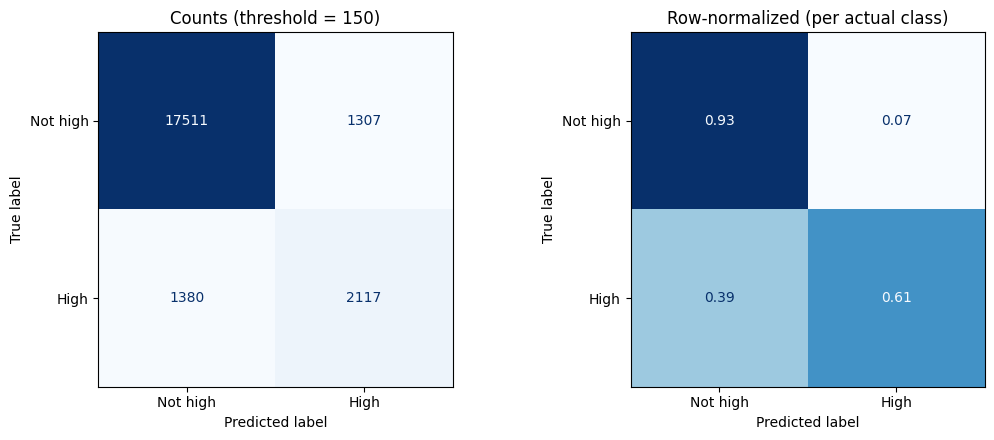


6-class confusion matrix:
                 Good  Moderate   USG  Unhealthy  Very unhealthy  Hazardous
Good               0       397   194         39              15          0
Moderate           0      2101  2504        742              26          2
USG                0       515  1999       1549              32          2
Unhealthy          0       219   991       6292            1211          8
Very unhealthy     0         9    35       1119            1522         37
Hazardous          0         3    17        200             515         20

                 precision    recall  f1-score   support

          Good      0.000     0.000     0.000       645
      Moderate      0.648     0.391     0.488      5375
           USG      0.348     0.488     0.406      4097
     Unhealthy      0.633     0.721     0.674      8721
Very unhealthy      0.458     0.559     0.504      2722
     Hazardous      0.290     0.026     0.049       755

      accuracy                          0.535     2

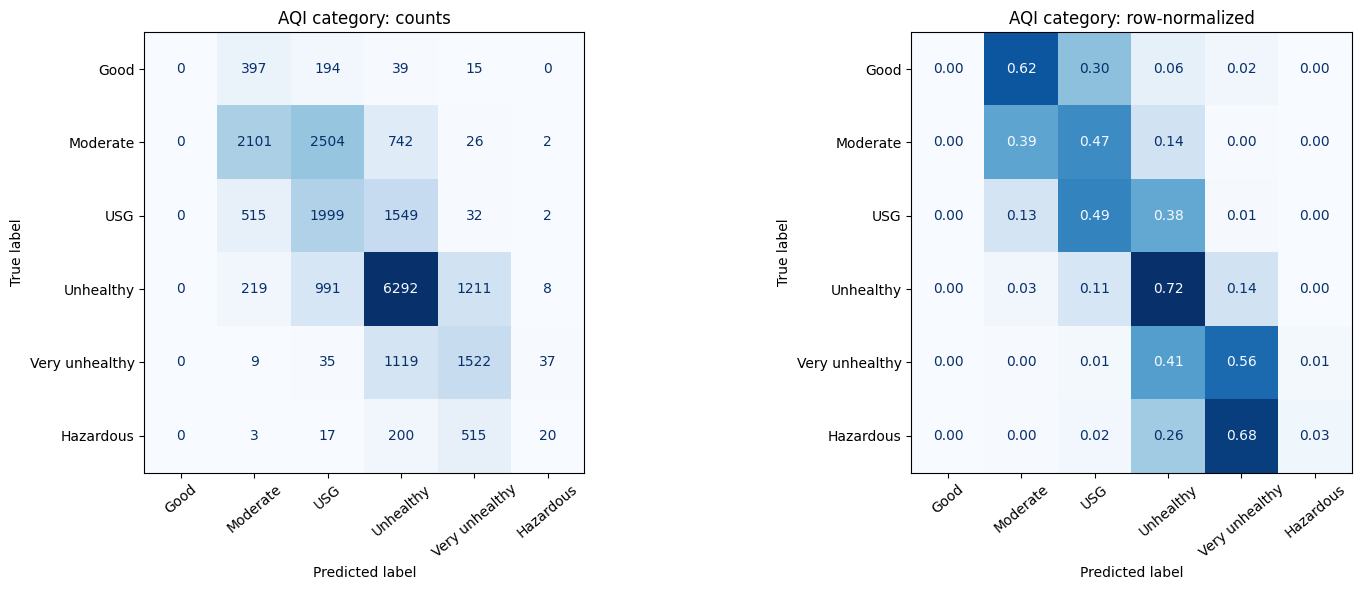

In [17]:
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay,
                             classification_report)

t = test.copy()
t["pred"] = pred          # LightGBM v1, 24h-ahead predictions on 2024

# =====================================================
# A) Binary: "high pollution" (PM2.5 > 150) yes/no
# =====================================================
THR = 150
y_true = (t["target"] > THR).astype(int)
y_pred = (t["pred"]   > THR).astype(int)

cm = confusion_matrix(y_true, y_pred)
tn, fp, fn, tp = cm.ravel()
print("Confusion matrix (rows = actual, cols = predicted):\n", cm)
print(f"\nTN={tn}  FP={fp}  FN={fn}  TP={tp}")
print(f"Precision = {tp/(tp+fp):.3f}   (when it alerts, how often is it right)")
print(f"Recall    = {tp/(tp+fn):.3f}   (how many real high hours it catches)")
print(f"F1        = {2*tp/(2*tp+fp+fn):.3f}")
print("\n", classification_report(y_true, y_pred, target_names=["Not high", "High"], digits=3))

fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
ConfusionMatrixDisplay.from_predictions(
    y_true, y_pred, display_labels=["Not high", "High"],
    cmap="Blues", values_format="d", colorbar=False, ax=ax[0])
ax[0].set_title(f"Counts (threshold = {THR})")
ConfusionMatrixDisplay.from_predictions(
    y_true, y_pred, display_labels=["Not high", "High"],
    normalize="true", cmap="Blues", values_format=".2f", colorbar=False, ax=ax[1])
ax[1].set_title("Row-normalized (per actual class)")
plt.tight_layout()
plt.savefig("fig_confusion_binary.png", dpi=200, bbox_inches="tight")
plt.show()

# =====================================================
# B) Multi-class: 6 AQI risk categories
# =====================================================
bins   = [-np.inf, 12, 35.4, 55.4, 150.4, 250.4, np.inf]
labels = ["Good", "Moderate", "USG", "Unhealthy", "Very unhealthy", "Hazardous"]

true_cat = pd.cut(t["target"], bins=bins, labels=False)
pred_cat = pd.cut(t["pred"],   bins=bins, labels=False)
idx = list(range(len(labels)))

cm6 = confusion_matrix(true_cat, pred_cat, labels=idx)
print("\n6-class confusion matrix:\n", pd.DataFrame(cm6, index=labels, columns=labels))
print("\n", classification_report(true_cat, pred_cat, labels=idx,
                                  target_names=labels, digits=3, zero_division=0))

fig, ax = plt.subplots(1, 2, figsize=(16, 6))
ConfusionMatrixDisplay(cm6, display_labels=labels).plot(
    ax=ax[0], cmap="Blues", values_format="d", colorbar=False, xticks_rotation=40)
ax[0].set_title("AQI category: counts")
ConfusionMatrixDisplay.from_predictions(
    true_cat, pred_cat, labels=idx, display_labels=labels, normalize="true",
    cmap="Blues", values_format=".2f", colorbar=False, xticks_rotation=40, ax=ax[1])
ax[1].set_title("AQI category: row-normalized")
plt.tight_layout()
plt.savefig("fig_confusion_aqi.png", dpi=200, bbox_inches="tight")
plt.show()

## 17. Alert threshold chosen on validation (2023), applied once to test (2024)

In [18]:
from sklearn.metrics import (precision_score, recall_score, f1_score,
                             confusion_matrix)

HIGH = 150

# 1. Sweep thresholds on VALIDATION (2023) only
pval = model.predict(X_val)
yv = (y_val > HIGH).astype(int)

rows = []
for th in range(60, 201, 5):
    yp = (pval > th).astype(int)
    rows.append((th,
                 precision_score(yv, yp, zero_division=0),
                 recall_score(yv, yp, zero_division=0),
                 f1_score(yv, yp, zero_division=0)))
sweep = pd.DataFrame(rows, columns=["thr", "precision", "recall", "f1"])
print(sweep.round(3).to_string(index=False))

# 2. Two ways to choose
thr_f1 = int(sweep.loc[sweep["f1"].idxmax(), "thr"])
cand = sweep[sweep["recall"] >= 0.80]
thr_rec = int(cand["thr"].max()) if len(cand) else int(sweep["thr"].min())
print(f"\nBest-F1 threshold (from val):        {thr_f1}")
print(f"Highest thr with recall>=80% (val):  {thr_rec}")

# 3. Apply to TEST once, no more tuning after this
yt = (y_test > HIGH).astype(int)
print(f"\n{'Rule':<14}{'Thr':>5}{'Prec':>8}{'Recall':>8}{'F1':>8}{'FP':>7}{'FN':>7}")
for name, th in [("Best F1", thr_f1), ("Recall>=80%", thr_rec), ("Naive 150", 150)]:
    yp = (pred > th).astype(int)
    tn, fp, fn, tp = confusion_matrix(yt, yp).ravel()
    print(f"{name:<14}{th:>5}{precision_score(yt, yp):>8.3f}{recall_score(yt, yp):>8.3f}"
          f"{f1_score(yt, yp):>8.3f}{fp:>7}{fn:>7}")

 thr  precision  recall    f1
  60      0.289   0.974 0.445
  65      0.313   0.967 0.472
  70      0.338   0.956 0.500
  75      0.366   0.949 0.529
  80      0.391   0.941 0.553
  85      0.415   0.933 0.575
  90      0.445   0.922 0.600
  95      0.473   0.914 0.624
 100      0.500   0.903 0.644
 105      0.524   0.891 0.660
 110      0.550   0.879 0.677
 115      0.572   0.864 0.688
 120      0.596   0.850 0.700
 125      0.622   0.830 0.711
 130      0.645   0.809 0.718
 135      0.669   0.790 0.724
 140      0.692   0.770 0.729
 145      0.712   0.741 0.726
 150      0.729   0.704 0.716
 155      0.751   0.669 0.708
 160      0.770   0.619 0.686
 165      0.790   0.579 0.668
 170      0.803   0.544 0.649
 175      0.817   0.509 0.627
 180      0.826   0.480 0.607
 185      0.840   0.455 0.590
 190      0.852   0.429 0.571
 195      0.864   0.403 0.550
 200      0.869   0.374 0.523

Best-F1 threshold (from val):        140
Highest thr with recall>=80% (val):  130

Rule            

## 18. Dedicated classifier for PM2.5 > 150 + precision-recall curve

Best iteration: 144
Chosen probability threshold (val): 0.353

PR-AUC (average precision) on test:
  Classifier      : 0.645
  Regressor (v1)  : 0.646
  Random baseline : 0.157

               precision    recall  f1-score   support

    Not high      0.944     0.907     0.925     18818
        High      0.588     0.712     0.644      3497

    accuracy                          0.877     22315
   macro avg      0.766     0.810     0.785     22315
weighted avg      0.888     0.877     0.881     22315



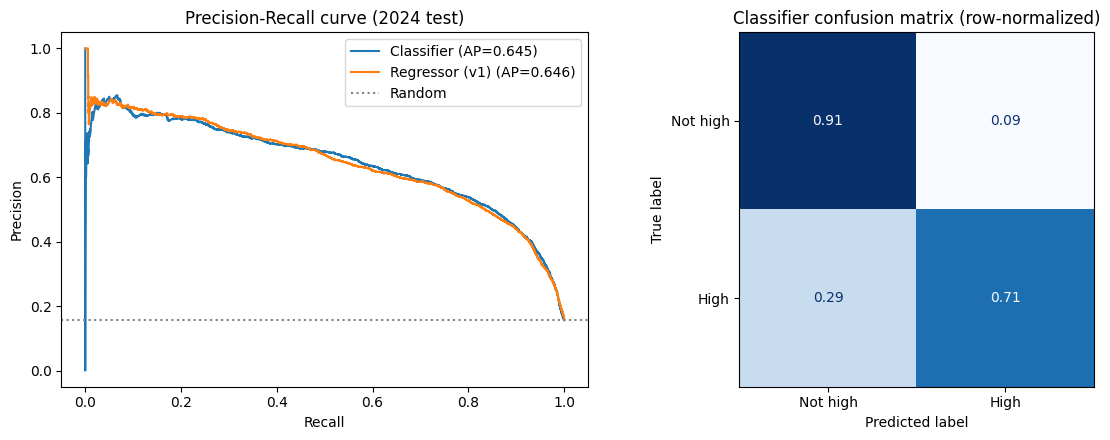

In [19]:
from sklearn.metrics import (average_precision_score, precision_recall_curve,
                             ConfusionMatrixDisplay, classification_report)

ytr_c = (y_train > HIGH).astype(int)
yva_c = (y_val   > HIGH).astype(int)
yte_c = (y_test  > HIGH).astype(int)

clf = lgb.LGBMClassifier(
    n_estimators=2000, learning_rate=0.03, num_leaves=31,
    subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
    random_state=42, n_jobs=-1, verbose=-1,
)
clf.fit(
    X_train, ytr_c,
    eval_set=[(X_val, yva_c)],
    eval_metric="average_precision",
    callbacks=[lgb.early_stopping(100, first_metric_only=True, verbose=False),
               lgb.log_evaluation(0)],
)
print("Best iteration:", clf.best_iteration_)

pv = clf.predict_proba(X_val)[:, 1]
pt = clf.predict_proba(X_test)[:, 1]

# Choose probability threshold on VALIDATION (best F1)
p_, r_, th_ = precision_recall_curve(yva_c, pv)
f1s = 2 * p_[:-1] * r_[:-1] / (p_[:-1] + r_[:-1] + 1e-12)
thr_c = th_[np.argmax(f1s)]
print(f"Chosen probability threshold (val): {thr_c:.3f}")

# Evaluate on TEST
yp_c = (pt > thr_c).astype(int)
print("\nPR-AUC (average precision) on test:")
print(f"  Classifier      : {average_precision_score(yte_c, pt):.3f}")
print(f"  Regressor (v1)  : {average_precision_score(yte_c, pred):.3f}")
print(f"  Random baseline : {yte_c.mean():.3f}")
print("\n", classification_report(yte_c, yp_c, target_names=["Not high", "High"], digits=3))

# Plots
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
for name, score in [("Classifier", pt), ("Regressor (v1)", pred)]:
    pp, rr, _ = precision_recall_curve(yte_c, score)
    ax[0].plot(rr, pp, label=f"{name} (AP={average_precision_score(yte_c, score):.3f})")
ax[0].axhline(yte_c.mean(), ls=":", color="gray", label="Random")
ax[0].set_xlabel("Recall"); ax[0].set_ylabel("Precision")
ax[0].set_title("Precision-Recall curve (2024 test)"); ax[0].legend()

ConfusionMatrixDisplay.from_predictions(
    yte_c, yp_c, display_labels=["Not high", "High"],
    normalize="true", cmap="Blues", values_format=".2f", colorbar=False, ax=ax[1])
ax[1].set_title("Classifier confusion matrix (row-normalized)")
plt.tight_layout()
plt.savefig("fig_pr_classifier.png", dpi=200, bbox_inches="tight")
plt.show()

## 19. Quantile models: 80% prediction interval + safer upper-bound alerts

alpha=0.1: best iter = 136
alpha=0.5: best iter = 151
alpha=0.9: best iter = 239

80% interval actual coverage : 79.2%  (ideal ~80%)
Average interval width       : 85.6 µg/m³
Median-model MAE             : 28.18

Alert rule              Recall  False alarms
Mean model > 150         0.605          1307
Median (q50) > 150       0.553          1019
Upper (q90) > 150        0.913          4356


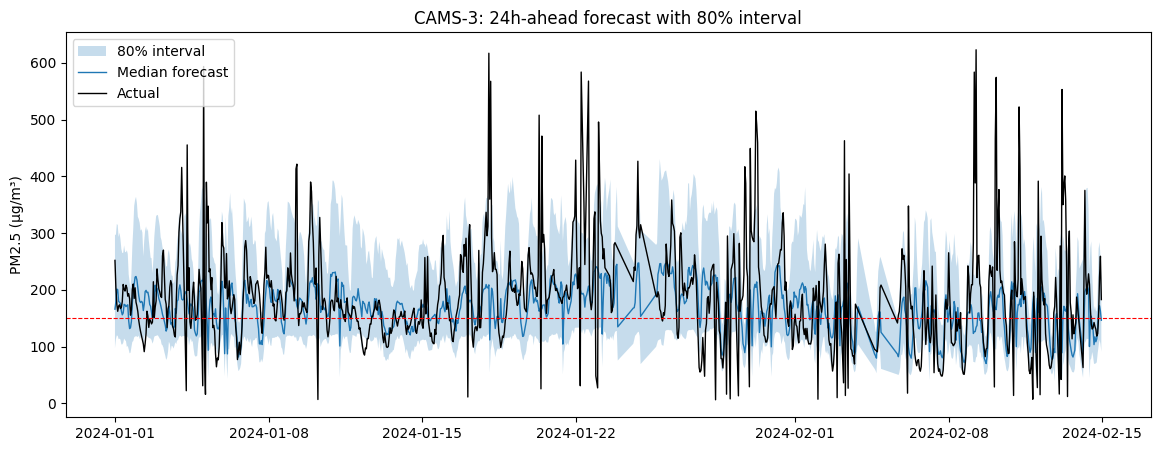

In [20]:
qs = [0.1, 0.5, 0.9]
qmodels, qpred = {}, {}

for a in qs:
    m = lgb.LGBMRegressor(
        objective="quantile", alpha=a,
        n_estimators=2000, learning_rate=0.03, num_leaves=31,
        subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
        random_state=42, n_jobs=-1, verbose=-1,
    )
    m.fit(X_train, y_train, eval_set=[(X_val, y_val)],
          callbacks=[lgb.early_stopping(100, verbose=False), lgb.log_evaluation(0)])
    qmodels[a] = m
    qpred[a] = m.predict(X_test)
    print(f"alpha={a}: best iter = {m.best_iteration_}")

# Sort so quantiles never cross (q10 <= q50 <= q90)
Q = np.sort(np.column_stack([qpred[a] for a in qs]), axis=1)
q10, q50, q90 = Q.T

yt_arr = y_test.values
cover = np.mean((yt_arr >= q10) & (yt_arr <= q90))
print(f"\n80% interval actual coverage : {cover*100:.1f}%  (ideal ~80%)")
print(f"Average interval width       : {np.mean(q90 - q10):.1f} µg/m³")
print(f"Median-model MAE             : {np.mean(np.abs(yt_arr - q50)):.2f}")

# Use the upper quantile as a "safe side" alert
actual_high = yt_arr > HIGH
print(f"\n{'Alert rule':<22}{'Recall':>8}{'False alarms':>14}")
for name, score in [("Mean model > 150", pred), ("Median (q50) > 150", q50), ("Upper (q90) > 150", q90)]:
    al = score > HIGH
    print(f"{name:<22}{(al & actual_high).sum()/actual_high.sum():>8.3f}{(al & ~actual_high).sum():>14}")

# Plot: CAMS-3, Jan 1 - Feb 15 2024
tq = test.copy()
tq["q10"], tq["q50"], tq["q90"] = q10, q50, q90
s = tq[(tq["station_id"] == "CAMS-3") & (tq["timestamp"] >= "2024-01-01") & (tq["timestamp"] < "2024-02-15")]
plt.figure(figsize=(14, 5))
plt.fill_between(s["timestamp"], s["q10"], s["q90"], alpha=0.25, label="80% interval")
plt.plot(s["timestamp"], s["q50"], lw=1, label="Median forecast")
plt.plot(s["timestamp"], s["target"], lw=1, color="k", label="Actual")
plt.axhline(HIGH, color="r", ls="--", lw=0.8)
plt.ylabel("PM2.5 (µg/m³)"); plt.title("CAMS-3: 24h-ahead forecast with 80% interval")
plt.legend(); plt.savefig("fig_quantile_band.png", dpi=200, bbox_inches="tight"); plt.show()

## 20. Better features (cyclic time, spike/trend, cross-station lags) — run this before the next two cells

In [21]:
from sklearn.metrics import mean_absolute_error

def build(df_in, horizons=(24,)):
    """Rebuild all features from raw columns + add the new ones + targets."""
    df = df_in.sort_values(["station_id", "timestamp"]).reset_index(drop=True)
    keep = [c for c in df.columns
            if not (c.startswith("pm25_") or c.startswith("target")
                    or c in ["hour", "month", "dow", "station_code"])]
    df = df[keep].copy()

    g = df.groupby("station_id")["pm2_5_ug_m3"]
    for lag in [1, 2, 3, 6, 12, 24, 48, 168]:
        df[f"pm25_lag{lag}"] = g.shift(lag)
    df["pm25_roll24"]  = g.transform(lambda s: s.rolling(24,  min_periods=12).mean())
    df["pm25_roll168"] = g.transform(lambda s: s.rolling(168, min_periods=72).mean())

    # NEW: spike / trend features
    df["pm25_max24"] = g.transform(lambda s: s.rolling(24, min_periods=12).max())
    df["pm25_std24"] = g.transform(lambda s: s.rolling(24, min_periods=12).std())
    df["d_now_1"]    = df["pm2_5_ug_m3"] - df["pm25_lag1"]
    df["d_1_24"]     = df["pm25_lag1"]   - df["pm25_lag24"]
    df["d_roll"]     = df["pm25_roll24"] - df["pm25_roll168"]

    # Time features (cyclic encoding so hour 23 and 0 are neighbours)
    df["hour"]  = df["timestamp"].dt.hour
    df["month"] = df["timestamp"].dt.month
    df["dow"]   = df["timestamp"].dt.dayofweek
    df["hour_sin"],  df["hour_cos"]  = np.sin(2*np.pi*df["hour"]/24),  np.cos(2*np.pi*df["hour"]/24)
    df["month_sin"], df["month_cos"] = np.sin(2*np.pi*df["month"]/12), np.cos(2*np.pi*df["month"]/12)
    df["station_code"] = df["station_id"].map({"CAMS-1": 0, "CAMS-2": 1, "CAMS-3": 2})

    # Wind direction -> sin/cos (if the column exists)
    for c in [c for c in df.columns if "wind_dir" in c and not c.endswith(("_sin", "_cos"))]:
        rad = np.deg2rad(df[c])
        df[c + "_sin"], df[c + "_cos"] = np.sin(rad), np.cos(rad)

    # NEW: other stations' PAST pm2.5 (lag1 and lag24 only, no future leakage)
    piv = df.pivot(index="timestamp", columns="station_id", values="pm2_5_ug_m3")
    for sid in piv.columns:
        for k in [1, 24]:
            df[f"pm25_{sid}_lag{k}"] = df["timestamp"].map(piv[sid].shift(k))

    # Targets
    gg = df.groupby("station_id")["pm2_5_ug_m3"]
    for h in horizons:
        df[f"target_{h}"] = gg.shift(-h)
    return df

def split(df, h):
    m = df.dropna(subset=[f"target_{h}", "pm25_lag1"])
    tr = m[m["timestamp"] <  "2023-01-01"]
    va = m[(m["timestamp"] >= "2023-01-01") & (m["timestamp"] < "2024-01-01")]
    te = m[m["timestamp"] >= "2024-01-01"]
    return tr, va, te

def fit_lgb(Xtr, ytr, Xva, yva, **kw):
    params = dict(n_estimators=2000, learning_rate=0.03, num_leaves=31,
                  subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
                  random_state=42, n_jobs=-1, verbose=-1)
    params.update(kw)
    m = lgb.LGBMRegressor(**params)
    m.fit(Xtr, ytr, eval_set=[(Xva, yva)], eval_metric="mae",
          callbacks=[lgb.early_stopping(100, first_metric_only=True, verbose=False),
                     lgb.log_evaluation(0)])
    return m

# ---- Build everything once (all horizons used later in the multi-horizon cell) ----
print("Columns available:", [c for c in clean.columns if not c.startswith(("pm25_", "target"))])
HS = [1, 6, 12, 24, 48, 72]
df3 = build(clean, horizons=HS)
FEATS = [c for c in df3.columns if c not in ("timestamp", "station_id") and not c.startswith("target_")]
print("Number of features:", len(FEATS))

# ---- Compare to v1 on the 24h target ----
tr3, va3, te3 = split(df3, 24)
m3 = fit_lgb(tr3[FEATS], tr3["target_24"], va3[FEATS], va3["target_24"])
p3 = m3.predict(te3[FEATS])

print(f"\nTest rows: v1={len(y_test)}  v3={len(te3)}")
print("--- TEST RESULTS (2024, 24h ahead) ---")
report("v1 (original)", y_test, pred)
report("v3 (new features)", te3["target_24"], p3)

imp3 = pd.Series(m3.feature_importances_, index=FEATS).sort_values(ascending=False)
print("\nTop 10 features:\n", imp3.head(10))

Columns available: ['timestamp', 'pm2_5_ug_m3', 'pm10_ug_m3', 'so2_ppb', 'no2_ppb', 'no_ppb', 'nox_ppb', 'co_ppm', 'o3_ppb', 'temp_c', 'rh_pct', 'wind_speed_ms', 'wind_dir_deg', 'barometric_pressure_hpa', 'solar_rad_wm2', 'rain_mm', 'station_id']
Number of features: 46

Test rows: v1=22315  v3=22315
--- TEST RESULTS (2024, 24h ahead) ---
v1 (original)                MAE= 29.35  RMSE= 47.85  R2=0.554
v3 (new features)            MAE= 29.18  RMSE= 47.63  R2=0.558

Top 10 features:
 pm25_roll168               308
temp_c                     268
pm2_5_ug_m3                263
pm25_roll24                231
month_cos                  216
pm25_lag168                179
barometric_pressure_hpa    174
pm25_lag24                 134
d_roll                     125
hour                       121
dtype: int32


## 21. Direct multi-horizon models (no recursive rollout)

Direct multi-horizon, full 2024 test set:

 horizon_h  model_MAE  persistence_MAE  improvement_%  iters
         1      14.15            15.34           7.72    204
         6      25.83            35.11          26.44    303
        12      28.02            40.73          31.19    135
        24      29.15            33.62          13.30    141
        48      31.45            38.47          18.24    137
        72      32.16            40.45          20.50    137


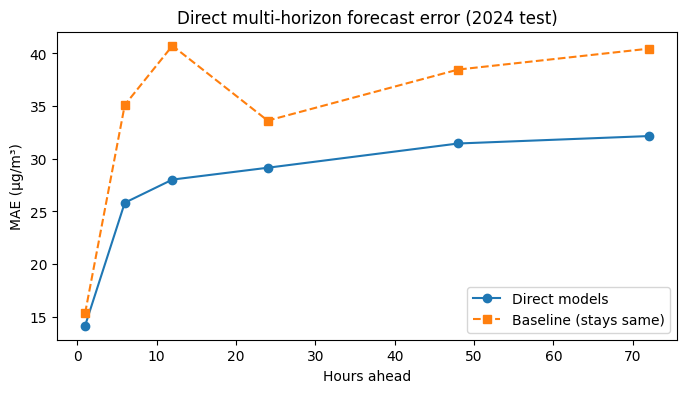

In [22]:
direct_models, rows = {}, []

for h in HS:
    tr, va, te = split(df3, h)
    m = fit_lgb(tr[FEATS], tr[f"target_{h}"], va[FEATS], va[f"target_{h}"])
    direct_models[h] = m

    p = m.predict(te[FEATS])
    y = te[f"target_{h}"].values
    persist = te["pm2_5_ug_m3"].values          # persistence: "stays same as now"
    fin = np.isfinite(persist)

    mae_m = mean_absolute_error(y[fin], p[fin])
    mae_b = mean_absolute_error(y[fin], persist[fin])
    rows.append((h, mae_m, mae_b, (1 - mae_m / mae_b) * 100, m.best_iteration_))

res_h = pd.DataFrame(rows, columns=["horizon_h", "model_MAE", "persistence_MAE", "improvement_%", "iters"])
print("Direct multi-horizon, full 2024 test set:\n")
print(res_h.round(2).to_string(index=False))

plt.figure(figsize=(8, 4))
plt.plot(res_h["horizon_h"], res_h["model_MAE"], "o-", label="Direct models")
plt.plot(res_h["horizon_h"], res_h["persistence_MAE"], "s--", label="Baseline (stays same)")
plt.xlabel("Hours ahead"); plt.ylabel("MAE (µg/m³)")
plt.title("Direct multi-horizon forecast error (2024 test)")
plt.legend(); plt.savefig("fig_direct_horizon.png", dpi=200, bbox_inches="tight"); plt.show()

## 22. Hyperparameter tuning with time-based CV (Optuna)

In [23]:
!pip install optuna -q
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

T = "target_24"
m24 = df3.dropna(subset=[T, "pm25_lag1"])
folds = [2020, 2021, 2022, 2023]     # validate on each year, train on everything before it

def cv_scores(params):
    maes = []
    for y in folds:
        tr = m24[m24["timestamp"] <  f"{y}-01-01"]
        va = m24[(m24["timestamp"] >= f"{y}-01-01") & (m24["timestamp"] < f"{y+1}-01-01")]
        m = fit_lgb(tr[FEATS], tr[T], va[FEATS], va[T], **params)
        maes.append(mean_absolute_error(va[T], m.predict(va[FEATS])))
    return maes

# 1. Baseline CV (your original-ish settings) -> gives error bars
base_maes = cv_scores(dict(num_leaves=63))
print("Baseline CV MAE per year:", dict(zip(folds, np.round(base_maes, 2))))
print(f"  mean = {np.mean(base_maes):.2f} ± {np.std(base_maes):.2f}")

# 2. Search
def objective(trial):
    params = dict(
        learning_rate=0.05,
        num_leaves=trial.suggest_int("num_leaves", 15, 127),
        min_child_samples=trial.suggest_int("min_child_samples", 20, 300),
        reg_lambda=trial.suggest_float("reg_lambda", 1e-3, 50, log=True),
        reg_alpha=trial.suggest_float("reg_alpha", 1e-3, 10, log=True),
        colsample_bytree=trial.suggest_float("colsample_bytree", 0.5, 1.0),
        subsample=trial.suggest_float("subsample", 0.5, 1.0),
    )
    return np.mean(cv_scores(params))

study = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=42))
study.optimize(objective, n_trials=25, timeout=1200)     # stops at 25 trials or 20 min

best_params = dict(study.best_params, learning_rate=0.05)
print("\nBest params:", best_params)
tuned_maes = cv_scores(best_params)
print("Tuned CV MAE per year:", dict(zip(folds, np.round(tuned_maes, 2))))
print(f"  mean = {np.mean(tuned_maes):.2f} ± {np.std(tuned_maes):.2f}")

# 3. Final check on untouched 2024 test
tr, va, te = split(df3, 24)
m_tuned = fit_lgb(tr[FEATS], tr[T], va[FEATS], va[T], **best_params)
p_tuned = m_tuned.predict(te[FEATS])

print("\n--- TEST RESULTS (2024, 24h ahead) ---")
report("v1 (original)", y_test, pred)
report("v3 (new features)", te3["target_24"], p3)
report("v3 + tuned", te[T], p_tuned)

m_tuned.booster_.save_model("pm25_lgbm_tuned.txt")

Baseline CV MAE per year: {2020: np.float64(27.51), 2021: np.float64(35.19), 2022: np.float64(31.29), 2023: np.float64(32.62)}
  mean = 31.65 ± 2.77

Best params: {'num_leaves': 18, 'min_child_samples': 155, 'reg_lambda': 0.1305998194415637, 'reg_alpha': 0.12247631564719086, 'colsample_bytree': 0.528338540331216, 'subsample': 0.84240694330944, 'learning_rate': 0.05}
Tuned CV MAE per year: {2020: np.float64(27.06), 2021: np.float64(34.48), 2022: np.float64(31.24), 2023: np.float64(32.31)}
  mean = 31.27 ± 2.70

--- TEST RESULTS (2024, 24h ahead) ---
v1 (original)                MAE= 29.35  RMSE= 47.85  R2=0.554
v3 (new features)            MAE= 29.18  RMSE= 47.63  R2=0.558
v3 + tuned                   MAE= 29.17  RMSE= 47.66  R2=0.557


## 23. Long-term outlook: honest framing (needs the monthly-forecast cells above)

Yearly mean PM2.5 trend: +1.41 µg/m³ per year (p = 0.189)
Best SARIMA val MAE = 12.64 vs seasonal-average = 12.69
-> SARIMA does not meaningfully beat the seasonal average.


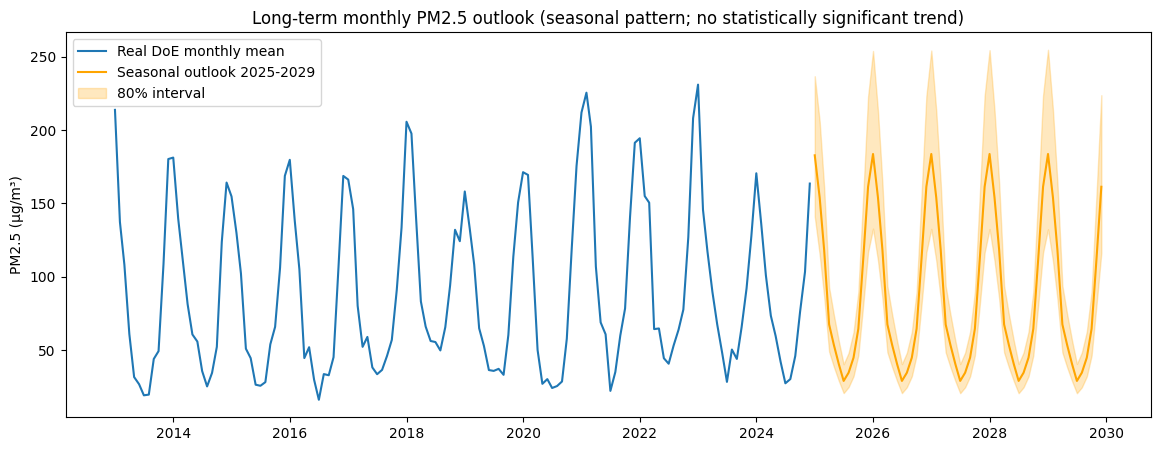

In [24]:
from scipy.stats import linregress

# 1. Is there actually a trend in the real data?
yearly = monthly.groupby(monthly.index.year).mean()
lr = linregress(yearly.index.values, yearly.values)
print(f"Yearly mean PM2.5 trend: {lr.slope:+.2f} µg/m³ per year (p = {lr.pvalue:.3f})")
trend_txt = ("no statistically significant trend" if lr.pvalue > 0.05
             else f"significant trend of {lr.slope:+.1f} µg/m³/yr")

# 2. Model vs baseline, stated plainly
best_mae = res.iloc[0]["MAE"]
print(f"Best SARIMA val MAE = {best_mae:.2f} vs seasonal-average = {base_mae:.2f}")
print("-> SARIMA does not meaningfully beat the seasonal average." if best_mae > 0.95 * base_mae
      else "-> SARIMA beats the seasonal average.")

# 3. Re-plot with an honest title
plt.figure(figsize=(14, 5))
plt.plot(monthly.index, monthly.values, label="Real DoE monthly mean")
plt.plot(mean.index, mean.values, color="orange", label="Seasonal outlook 2025-2029")
plt.fill_between(mean.index, lo, hi, color="orange", alpha=0.25, label="80% interval")
plt.ylabel("PM2.5 (µg/m³)")
plt.title(f"Long-term monthly PM2.5 outlook (seasonal pattern; {trend_txt})")
plt.legend()
plt.savefig("fig_longterm_forecast.png", dpi=200, bbox_inches="tight"); plt.show()

## 24. 72h forecast that skips stations with stale data (needs the recursive-forecast cell above)


CAMS-1: last real data = 2024-12-31 23:00:00
  Day +1:  164.4 µg/m³ -> Very unhealthy
  Day +2:  166.8 µg/m³ -> Very unhealthy
  Day +3:  164.8 µg/m³ -> Very unhealthy

CAMS-2: last real data = 2024-12-31 23:00:00
  Day +1:  143.6 µg/m³ -> Unhealthy
  Day +2:  157.1 µg/m³ -> Very unhealthy
  Day +3:  163.0 µg/m³ -> Very unhealthy

CAMS-3: last good data = 2024-12-16 10:00:00 (15.5 days before end of dataset) -> forecast SKIPPED (stale)


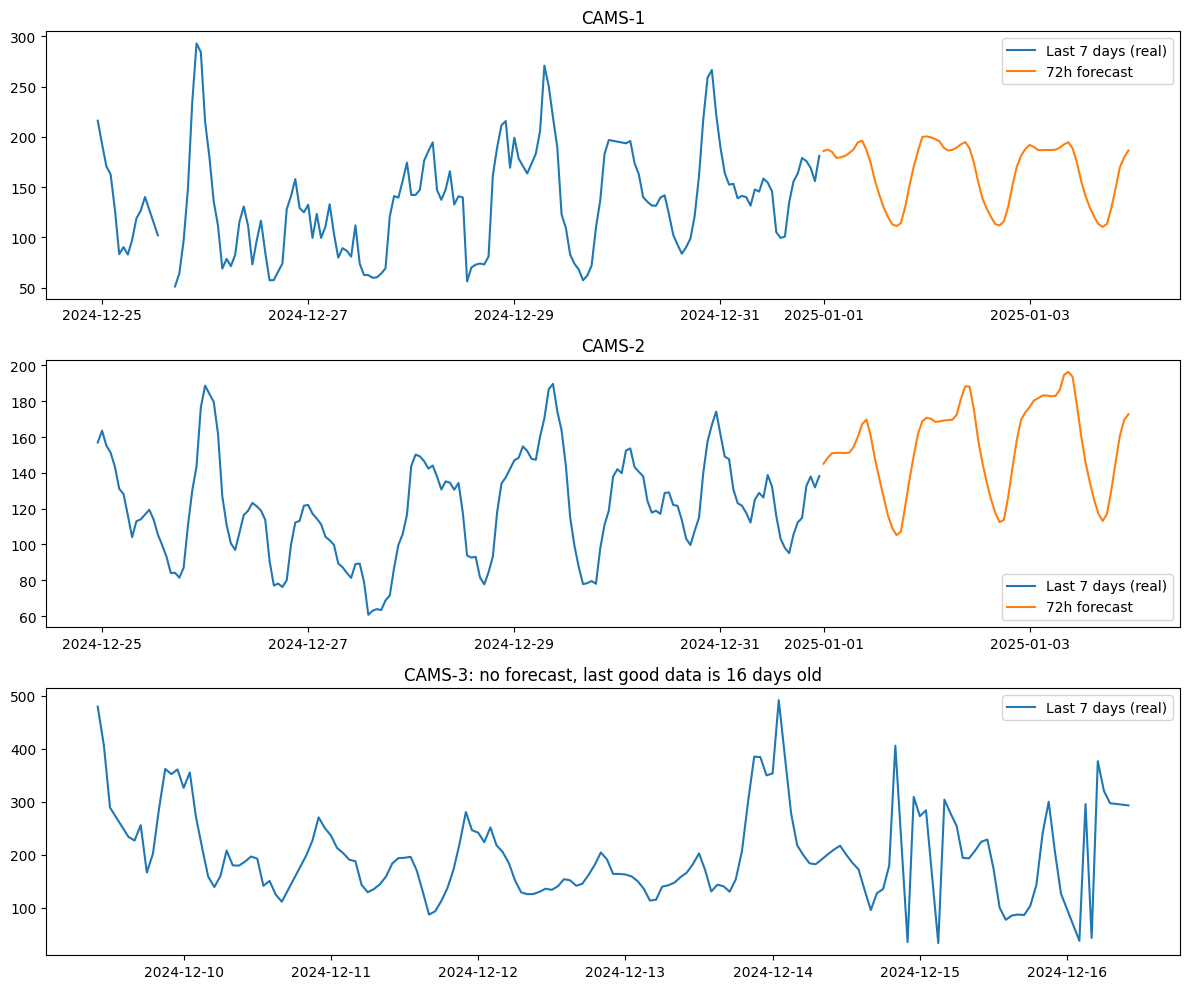

In [25]:
MAX_AGE_H = 48                       # skip a station if its last good data is older than this
end_ts = d["timestamp"].max()

fig, axes = plt.subplots(3, 1, figsize=(12, 10))
for ax, (sid, grp) in zip(axes, d.groupby("station_id")):
    s = grp.set_index("timestamp")["pm2_5_ug_m3"]
    v = s.values
    i = next(j for j in range(len(v) - 1, 168, -1)
             if np.isfinite(v[j]) and np.isfinite(v[j-168:j+1]).sum() >= 120)
    age_h = (end_ts - s.index[i]) / pd.Timedelta(hours=1)

    ax.plot(s.index[i-168:i+1], v[i-168:i+1], label="Last 7 days (real)")

    if age_h > MAX_AGE_H:
        print(f"\n{sid}: last good data = {s.index[i]} ({age_h/24:.1f} days before end of dataset) -> forecast SKIPPED (stale)")
        ax.set_title(f"{sid}: no forecast, last good data is {age_h/24:.0f} days old")
        ax.legend()
        continue

    fc = rollout(v[i-168:i+1], s.index[i], code_map[sid])
    daily = fc.reshape(-1, 24).mean(axis=1)
    print(f"\n{sid}: last real data = {s.index[i]}")
    for n, x in enumerate(daily, 1):
        print(f"  Day +{n}: {x:6.1f} µg/m³ -> {risk_level(x)}")
    ax.plot(pd.date_range(s.index[i], periods=len(fc) + 1, freq="h")[1:], fc, label=f"{len(fc)}h forecast")
    ax.set_title(sid); ax.legend()

plt.tight_layout(); plt.savefig("fig_forecast.png", dpi=200, bbox_inches="tight"); plt.show()

## 25. Package figures + model files and download results.zip

In [26]:
!zip -q results.zip fig_*.png anomalies.csv forecast_results_2024.csv longterm_forecast_2025_2029.csv pm25_lgbm.txt pm25_lgbm_tuned.txt
from google.colab import files
files.download("results.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>